LipidTOX droplets (red, idx0) · LAMP1-RFP lysosomes (orange, idx1) · galectin-GFP (green, idx2) · Hoechst nuclei (blue, idx3)

**Two CSVs per image folder in `Results/`:**
- `<folder>_galectin_LAMP1_lipidtox_analysis.csv`: one row per triple-positive (green + red + orange) cell. Cells with 0 nucleus area or 0 cytoplasm area are removed (they are Cellpose fragments of a larger cell). Cells touching the image border are also removed (`EXCLUDE_EDGE_CELLS`), because these partial cells were the main outliers.
- `<folder>_galectin_LAMP1_lipidtox_per_image_blob.csv`: one row per image. Each galectin-GFP cell is taken whole from the green signal as a solid blob, which merges the Cellpose fragments back together. All eligible blobs in the image (nucleus > 0, cytoplasm > 0, red + orange present, not on the border) are merged into one region and measured. `N_Nuclei` counts the nuclei inside, and green dots use one local threshold per whole blob.

Every exclusion and its reason is saved in `Results/masks/<folder>/<image>/cell_eligibility.csv` and `blob_eligibility.csv`. MFIs use the raw channel.

## Imports
Install dependencies first.

In [1]:
%matplotlib inline
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap

import czifile
from scipy import ndimage as ndi
from skimage import exposure, morphology
from skimage.filters import threshold_otsu, gaussian
from skimage.measure import label, regionprops
from skimage.morphology import remove_small_objects, disk
from skimage.segmentation import relabel_sequential, watershed

## Parameters & segmentation method

In [ ]:
BASE_DIR = "."
IMAGE_FOLDER_NAMES = [
    "galectin test images",
    "M17D_52926_siRNA_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst",
    "M17D_60426_siRNA_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst",
    "M17D_60526_siRNA_OA_Fed_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst",
    "M17D_60926_siRNA_OA_Fed_galectinGFP_LAMP1RFP_LipidTOXfr_Hoechst",
    "M17D_61126_siRNA_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst",
    "M17D_61826_siRNA_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst",
    "M17D_61826_siRNA_OA_Fed_galectinGFP_LAMP1RFP_LipidTOXfr_Hoechst",
]


def resolve_image_folder(name):
    """Return the first folder that exists for name."""
    for cand in (os.path.join(BASE_DIR, name), os.path.join(BASE_DIR, "images", name)):
        if os.path.isdir(cand):
            return cand
    return os.path.join(BASE_DIR, name)


IMAGE_FOLDERS = [resolve_image_folder(n) for n in IMAGE_FOLDER_NAMES]

FILE_EXTENSION = "*.czi"
RESULTS_FOLDER = "Results"
MASK_FOLDER = os.path.join(RESULTS_FOLDER, "masks")
CSV_SUFFIX = "galectin_LAMP1_lipidtox_analysis.csv"  # final CSV suffix
SHOW_PLOTS = True  # skip QC panels on long runs

# Channel order: red, orange, green, blue
CHANNEL_ORDER = {"red": 0, "orange": 1, "green": 2, "blue": 3}

USE_CELLPOSE = True
USE_GPU = True

# Cell segmentation: Cellpose cyto3 on orange + red
CYTO_SEG_CHANNELS = ["orange", "red"]
CYTO_DIAMETER = 110  # larger keeps big cells whole
CYTO_FLOW_THRESH = 0.8  # more lenient
CYTO_PROB_THRESH = -3.0  # catches dimmer cells
CELL_MIN_AREA = 300  # drop tiny objects

# Hybrid fill: recover missed cells from nuclei
CELL_FILL_FG_THRESH = 0.06  # composite cutoff for cell foreground
CELL_GROW_DIST = 70  # max growth from a nucleus

# Nucleus segmentation: permissive on blue
NUC_DIAMETER = 150  # measured ~166 px; 50 split every nucleus into 2-6 pieces
NUC_FLOW_THRESH = 0.9  # permissive
NUC_PROB_THRESH = -6.0  # very sensitive
NUC_MIN_AREA = 30
NUC_INTENSITY_FLOOR = 0.06  # anything above this is nucleus too

# Green-positive cell: threshold on green
GREEN_FILL_SIGMA = 2.0  # smooth green before thresholding
GREEN_FILL_THRESH = 0.10  # green above this counts
GREEN_FILL_FRAC = 0.50  # green-positive cutoff

# Fallback if Cellpose is off
SEG_SMOOTH_SIGMA = 10
SEG_FG_FLOOR = 0.05
SEG_GREEN_BOOST = 3.0
NUCLEUS_MIN_SIZE = 30
NUCLEUS_FLOOR = 0.05

# Inclusion analysis
GREEN_TOPHAT_RADIUS = 8
GREEN_CONTRAST_THRESH = 0.010
GREEN_MIN_BRIGHTNESS = 0.05
GREEN_MIN_SIZE = 4
GREEN_MAX_SIZE = 400
GREEN_LOCAL_ZSCORE = 1.5
GREEN_LOCAL_PCTL = 84.9

# Red lipid droplets
RED_TOPHAT_RADIUS = 12
RED_PCTL_THRESH = 99.0
RED_MIN_SIZE = 6
RED_MAX_SIZE = 1500

# Orange lysosomes
ORANGE_TOPHAT_RADIUS = 12
ORANGE_PCTL_THRESH = 98.5
ORANGE_MIN_SIZE = 6
ORANGE_MAX_SIZE = 1500

# Cell-level triple-positive inclusion
# Require meaningful detected red and corrected-orange area inside each green cell.
TRIPLE_RED_MIN_AREA = RED_MIN_SIZE
TRIPLE_ORANGE_MIN_AREA = ORANGE_MIN_SIZE

# Per-cell export filters. A cell with 0 nucleus or 0 cytoplasm area is a
# Cellpose fragment, not a cell; such cells are always dropped.
EXCLUDE_EDGE_CELLS = True  # partial cells cut by the image border

# Per-image green blob (one row per image). Each galectin-GFP cell is taken
# whole from smoothed green > GREEN_FILL_THRESH, then closed, hole-filled and
# smoothed into a solid blob.
BLOB_CLOSE_RADIUS = 5
BLOB_OPEN_RADIUS = 5
BLOB_MIN_AREA = 3_000
BLOB_NUCLEUS_MIN_FRACTION = 0.5  # a nucleus counts when >=50% of it is in the region
EXCLUDE_EDGE_BLOBS = True
BLOB_CSV_SUFFIX = "galectin_LAMP1_lipidtox_per_image_blob.csv"

# Bleed-through: red to orange
BLEED_CONTAINMENT_THRESH = 0.90
BLEED_PROTECT_GREEN = True
TOUCH_DILATION = 1
STRUCTURE_CLOSE_RADIUS = 1

os.makedirs(RESULTS_FOLDER, exist_ok=True)
os.makedirs(MASK_FOLDER, exist_ok=True)

cyto_model = nuc_model = None
if USE_CELLPOSE:
    from cellpose import models

    def load_cellpose_model(model_type):
        """Load one Cellpose model, falling back to CPU if GPU setup fails."""
        try:
            return models.Cellpose(gpu=USE_GPU, model_type=model_type)
        except Exception as exc:
            if not USE_GPU:
                raise
            print(f"  {model_type} GPU initialization failed ({exc}); using CPU")
            return models.Cellpose(gpu=False, model_type=model_type)

    print("Initializing Cellpose cyto3 and nuclei models...")
    cyto_model = load_cellpose_model("cyto3")
    nuc_model = load_cellpose_model("nuclei")
    print(f"  Cellpose models ready | GPU requested={USE_GPU}")
else:
    print("Using intensity-based segmentation (Cellpose disabled).")
print("Parameters set.")

Initializing Cellpose cyto3 and nuclei models...


  Cellpose models ready | GPU requested=True
Parameters set.


## Loading & normalization

In [3]:
def normalize_image(image):
    """Min-max normalize to float64 [0, 1].  Used by the INCLUSION ANALYSIS
    (green dots, lipids, lysosomes) — do not change."""
    img = image.astype(np.float64)
    mn, mx = img.min(), img.max()
    return np.zeros_like(img) if mx == mn else (img - mn) / (mx - mn)


def pct_norm(image, lo=1.0, hi=99.5):
    """Percentile contrast-stretch to float32 [0, 1].  Used for SEGMENTATION.

    Min-max normalization fails on these images because single saturated pixels
    (raw max ~65535) crush the real cell signal to ~0.01. Clipping at the 1st/
    99.5th percentiles keeps the cytoplasm/nucleus signal in a usable range so
    Cellpose can actually see the cells."""
    image = image.astype(np.float32)
    p_lo, p_hi = np.percentile(image, (lo, hi))
    if p_hi <= p_lo:
        return np.zeros_like(image)
    return np.clip((image - p_lo) / (p_hi - p_lo), 0, 1)


def boost_contrast_visual(image):
    """Percentile stretch for DISPLAY ONLY."""
    p_lo, p_hi = np.percentile(image, (1, 99.5))
    return exposure.rescale_intensity(image, in_range=(p_lo, p_hi))


def _disk_filter(image, radius, filter_1d, combine):
    """Flat-disk min/max filter, bit-identical to skimage's erosion/dilation
    (scipy 'reflect' border) but ~10-20x faster for large disks: a disk is a
    stack of centred rows, so the 2-D filter is the min/max of shifted 1-D
    row filters, one per distinct row width."""
    footprint = morphology.disk(radius)
    is_bool = image.dtype == bool
    values = image.view(np.uint8) if is_bool else image
    padded = np.pad(values, radius, mode="symmetric")  # numpy 'symmetric' == scipy 'reflect'
    height, width = values.shape
    by_width, out = {}, None
    for dy in range(footprint.shape[0]):
        half = (int(footprint[dy].sum()) - 1) // 2
        if half not in by_width:
            by_width[half] = filter_1d(padded, 2 * half + 1, axis=1)[:, radius:radius + width]
        rows = by_width[half][dy:dy + height]
        out = rows.copy() if out is None else combine(out, rows, out=out)
    return out.view(bool) if is_bool else out


def disk_opening(image, radius):
    """Same result as morphology.opening(image, disk(radius))."""
    eroded = _disk_filter(image, radius, ndi.minimum_filter1d, np.minimum)
    return _disk_filter(eroded, radius, ndi.maximum_filter1d, np.maximum)


def disk_closing(image, radius):
    """Same result as morphology.closing(image, disk(radius))."""
    dilated = _disk_filter(image, radius, ndi.maximum_filter1d, np.maximum)
    return _disk_filter(dilated, radius, ndi.minimum_filter1d, np.minimum)


def white_tophat_disk(image, radius):
    """Same result as morphology.white_tophat(image, disk(radius)) for float images."""
    return image - disk_opening(image, radius)


def binary_closing_disk(mask, radius):
    """Same result as the deprecated morphology.binary_closing(mask, disk(radius)):
    dilation with an empty border, then erosion with a filled border."""
    footprint = disk(radius)
    return ndi.binary_erosion(ndi.binary_dilation(mask, footprint), footprint, border_value=1)


def load_four_channels(filepath):
    """Load 4-channel .czi -> dict {'red','orange','green','blue'} per CHANNEL_ORDER."""
    try:
        czi = czifile.CziFile(filepath)
        img = np.squeeze(czi.asarray())
    except Exception as e:
        print(f"  [ERROR] File load failed: {e}")
        return None
    if img.ndim == 3 and 4 in img.shape:
        ch_axis = int(np.where(np.array(img.shape) == 4)[0][0])
        img = np.moveaxis(img, ch_axis, 0)
    else:
        print(f"  [ERROR] Expected a 4-channel image, got shape {img.shape}")
        return None
    return {name: img[idx] for name, idx in CHANNEL_ORDER.items()}

## Mask functions

In [4]:


def drop_small_labels(labels, min_area):
    """Remove labels smaller than min_area and relabel 1..N."""
    labels = labels.astype(np.int32)
    counts = np.bincount(labels.ravel())
    small = np.flatnonzero(counts < min_area)
    small = small[small != 0]  # keep background
    if small.size:
        labels[np.isin(labels, small)] = 0
    return relabel_sequential(labels)[0]


def cyto_composite(seg):
    """Max of the cell-segmentation channels."""
    return np.maximum.reduce([seg[c] for c in CYTO_SEG_CHANNELS])


def segment_whole_cells_cellpose(seg):
    """Cell mask from Cellpose cyto3 on orange + red."""
    composite = cyto_composite(seg)
    masks, _, _, _ = cyto_model.eval(
        composite, diameter=CYTO_DIAMETER, channels=[0, 0],
        flow_threshold=CYTO_FLOW_THRESH, cellprob_threshold=CYTO_PROB_THRESH,
        normalize=True, resample=True,
    )
    final = drop_small_labels(masks, CELL_MIN_AREA)
    print(f"    Cells (cyto3 orange+red, composite-only): {final.max()}")
    return final


def segment_nucleus(seg):
    """Return the nucleus mask and labeled nuclei."""
    blue = seg["blue"]
    masks, _, _, _ = nuc_model.eval(
        (blue * 255).astype(np.uint8), diameter=NUC_DIAMETER, channels=[0, 0],
        flow_threshold=NUC_FLOW_THRESH, cellprob_threshold=NUC_PROB_THRESH,
        normalize=True, resample=True,
    )
    cp_nuc = masks > 0
    labeled_nuclei = drop_small_labels(masks, NUC_MIN_AREA)  # nuclei for seeding

    # Catch bright blue pixels the model missed
    bsm = gaussian(blue, sigma=2)
    try:
        thr = max(threshold_otsu(bsm) * 0.5, NUC_INTENSITY_FLOOR)
    except Exception:
        thr = NUC_INTENSITY_FLOOR
    inten = bsm > thr
    inten = binary_closing_disk(inten, 2)
    inten = ndi.binary_fill_holes(inten)
    inten = remove_small_objects(inten, max_size=NUC_MIN_AREA)

    nucleus = cp_nuc | inten
    print(f"    Nucleus (cellpose {int(masks.max())} + intensity union): "
          f"{int(nucleus.sum())} px")
    return nucleus, labeled_nuclei


def classify_green_positive(labeled_cells, green_seg):
    """Return cells whose masks are substantially filled with green signal."""
    green_smoothed = gaussian(green_seg, sigma=GREEN_FILL_SIGMA)
    green_on = green_smoothed > GREEN_FILL_THRESH
    n_cells = int(labeled_cells.max())
    areas = np.bincount(labeled_cells.ravel(), minlength=n_cells + 1)
    green_areas = np.bincount(labeled_cells[green_on], minlength=n_cells + 1)
    green_ids, fills = [], {}
    for cid in range(1, n_cells + 1):
        area = int(areas[cid])
        if area == 0:
            continue
        fill = float(green_areas[cid]) / area
        fills[cid] = fill
        if fill >= GREEN_FILL_FRAC:
            green_ids.append(cid)
    return green_ids, fills


def classify_triple_positive_cells(labeled_cells, green_positive_ids, fills,
                                   red_mask, orange_mask):
    """Select cells positive for green, red, and corrected orange signal.

    Triple-positive is a cell-level eligibility rule. The three signals do not
    need to overlap at the same pixel; pixel overlap remains a separate metric.
    """
    green_set = set(int(cid) for cid in green_positive_ids)
    n_cells = int(labeled_cells.max())
    red_areas = np.bincount(labeled_cells[red_mask], minlength=n_cells + 1)
    orange_areas = np.bincount(labeled_cells[orange_mask], minlength=n_cells + 1)
    triple_ids, eligibility = [], {}
    for cid in range(1, n_cells + 1):
        red_area = int(red_areas[cid])
        orange_area = int(orange_areas[cid])
        green_positive = cid in green_set
        red_positive = red_area >= TRIPLE_RED_MIN_AREA
        orange_positive = orange_area >= TRIPLE_ORANGE_MIN_AREA
        triple_positive = green_positive and red_positive and orange_positive
        eligibility[cid] = {
            "Green_Fill_Fraction": round(float(fills.get(cid, 0.0)), 6),
            "Green_Positive": bool(green_positive),
            "Red_Positive_Area_px": red_area,
            "Red_Positive": bool(red_positive),
            "Orange_Positive_Area_px": orange_area,
            "Orange_Positive": bool(orange_positive),
            "Triple_Positive_Cell": bool(triple_positive),
        }
        if triple_positive:
            triple_ids.append(cid)
    return triple_ids, eligibility


def fill_missed_cells_from_nuclei(cyto_cells, nuclei, composite):
    """Recover missed cells from nuclei."""
    cells = cyto_cells.astype(np.int32).copy()
    n_cyto = int(cells.max())

    # Existing cells plus one new label per missed nucleus
    seeds = cells.copy()
    next_label = n_cyto + 1
    for nid in np.unique(nuclei):
        if nid == 0:
            continue
        nuc = nuclei == nid
        if (cells[nuc] > 0).mean() < 0.5:  # nucleus not inside a cell
            seeds[nuc & (cells == 0)] = next_label
            next_label += 1
    n_added = next_label - 1 - n_cyto
    if n_added == 0:
        print(f"    Hybrid cells: {n_cyto} (+0 recovered)")
        return cells

    # Grow new seeds within signal, up to a max distance
    dist_from_seed = ndi.distance_transform_edt(seeds == 0)
    foreground = composite > CELL_FILL_FG_THRESH
    foreground = ndi.binary_fill_holes(morphology.closing(foreground, disk(3))) | (seeds > 0)
    foreground = foreground & (dist_from_seed <= CELL_GROW_DIST)
    grown = watershed(
        np.where(foreground, dist_from_seed, dist_from_seed.max() + 1),
        markers=seeds, mask=foreground
    )
    new_pixels = (grown > n_cyto) & (cyto_cells == 0)  # never overwrite cyto3 cells
    cells[new_pixels] = grown[new_pixels]
    final, _, _ = relabel_sequential(cells)
    print(f"    Hybrid cells: {int(final.max())} (+{n_added} recovered)")
    return final


def make_nucleus_mask(blue):
    """Intensity-only nucleus fallback."""
    bsm = gaussian(blue, sigma=SEG_SMOOTH_SIGMA)
    bsm = normalize_image(bsm)
    nuc = bsm > SEG_FG_FLOOR
    nuc = binary_closing_disk(nuc, 2)
    nuc = remove_small_objects(nuc, max_size=NUCLEUS_MIN_SIZE)
    return nuc


def segment_cells_intensity(green, blue):
    """Intensity-based cell fallback."""
    g = normalize_image(gaussian(green, sigma=SEG_SMOOTH_SIGMA))
    b = normalize_image(gaussian(blue, sigma=SEG_SMOOTH_SIGMA))
    score = np.maximum(g * SEG_GREEN_BOOST, b)
    fg = score > SEG_FG_FLOOR
    fg = binary_closing_disk(fg, 3)
    final = drop_small_labels(label(fg), CELL_MIN_AREA)
    print(f"    Cells (intensity): {final.max()}")
    return final


def touches_image_edge(labels):
    """IDs of labels with any pixel on the image border."""
    border = np.concatenate([labels[0], labels[-1], labels[:, 0], labels[:, -1]])
    return {int(i) for i in np.unique(border) if i}


def count_nuclei_in_regions(regions, labeled_nuclei):
    """Nuclei per region: a nucleus counts for the region holding at least
    BLOB_NUCLEUS_MIN_FRACTION of its area. Returns an array indexed by region ID."""
    n_regions = int(regions.max())
    n_nuclei = int(labeled_nuclei.max())
    both = (regions > 0) & (labeled_nuclei > 0)
    pairs = np.bincount(
        labeled_nuclei[both].astype(np.int64) * (n_regions + 1) + regions[both],
        minlength=(n_nuclei + 1) * (n_regions + 1),
    ).reshape(n_nuclei + 1, n_regions + 1)
    nucleus_areas = np.bincount(labeled_nuclei.ravel(), minlength=n_nuclei + 1)
    counts = np.zeros(n_regions + 1, dtype=int)
    for nid in range(1, n_nuclei + 1):
        rid = int(pairs[nid].argmax())
        if rid and pairs[nid, rid] >= BLOB_NUCLEUS_MIN_FRACTION * nucleus_areas[nid]:
            counts[rid] += 1
    return counts


def segment_green_blobs(green_seg):
    """Whole galectin-GFP cells as solid blobs, straight from the green signal,
    so a cell split by Cellpose becomes one region again."""
    green_on = gaussian(green_seg, sigma=GREEN_FILL_SIGMA) > GREEN_FILL_THRESH
    blobs = ndi.binary_fill_holes(disk_closing(green_on, BLOB_CLOSE_RADIUS))
    blobs = disk_opening(blobs, BLOB_OPEN_RADIUS)
    return drop_small_labels(label(blobs), BLOB_MIN_AREA)


def bridge_small_gaps(mask, radius=STRUCTURE_CLOSE_RADIUS):
    if radius <= 0:
        return mask
    return binary_closing_disk(mask, radius)


# Inclusion analysis
def detect_green_dots(green_norm, labeled_cells):
    """Cell-aware galectin puncta."""
    tophat = white_tophat_disk(green_norm, GREEN_TOPHAT_RADIUS)
    candidate = ((tophat > GREEN_CONTRAST_THRESH) &
                 (green_norm > GREEN_MIN_BRIGHTNESS) & (labeled_cells > 0))
    candidate = remove_small_objects(candidate, max_size=GREEN_MIN_SIZE)
    final = np.zeros_like(candidate, dtype=bool)
    for cid, window in enumerate(ndi.find_objects(labeled_cells), start=1):
        if window is None:
            continue
        cell_mask = labeled_cells[window] == cid
        green_here = green_norm[window]
        vals = green_here[cell_mask]
        local_thr = max(GREEN_MIN_BRIGHTNESS,
                        float(vals.mean()) + GREEN_LOCAL_ZSCORE * float(vals.std() or 1e-6),
                        float(np.percentile(vals, GREEN_LOCAL_PCTL)))
        final[window] |= candidate[window] & cell_mask & (green_here >= local_thr)
    final = bridge_small_gaps(final)
    final = remove_small_objects(final, max_size=GREEN_MIN_SIZE)
    for p in regionprops(label(final)):
        if p.area > GREEN_MAX_SIZE:
            final[p.slice][p.image] = False
    return final


def detect_bright_puncta(channel_norm, tophat_radius, pctl_thresh, min_size, max_size):
    tophat = white_tophat_disk(channel_norm, tophat_radius)
    nonzero = tophat[tophat > 0]
    if nonzero.size == 0:
        return np.zeros_like(channel_norm, dtype=bool)
    mask = tophat > np.percentile(nonzero, pctl_thresh)
    mask = bridge_small_gaps(mask)
    mask = remove_small_objects(mask, max_size=min_size)
    for p in regionprops(label(mask)):
        if p.area > max_size:
            mask[p.slice][p.image] = False
    return mask


def remove_bleedthrough(orange_mask, red_mask, green_dots=None,
                        thresh=BLEED_CONTAINMENT_THRESH, protect_green=BLEED_PROTECT_GREEN):
    orange_lbl = label(orange_mask)
    red_lbl = label(red_mask)
    red_area = {p.label: p.area for p in regionprops(red_lbl)}
    corrected = orange_mask.copy()
    bleed = np.zeros_like(orange_mask, dtype=bool)
    for o in regionprops(orange_lbl):
        r0, c0, r1, c1 = o.bbox
        o_crop = orange_lbl[r0:r1, c0:c1] == o.label
        red_crop = red_lbl[r0:r1, c0:c1]
        overlap = np.unique(red_crop[o_crop]); overlap = overlap[overlap > 0]
        if overlap.size == 0:
            continue
        if protect_green and green_dots is not None and np.any(o_crop & green_dots[r0:r1, c0:c1]):
            continue
        red_union = np.isin(red_crop, overlap)
        frac_orange_in_red = (o_crop & red_union).sum() / o.area
        red_in_orange = any(((red_crop == rl) & o_crop).sum() / red_area[rl] >= thresh
                            for rl in overlap)
        if frac_orange_in_red >= thresh or red_in_orange:
            corr_crop = corrected[r0:r1, c0:c1]; bleed_crop = bleed[r0:r1, c0:c1]
            corr_crop[o_crop] = False; bleed_crop[o_crop] = True
            corrected[r0:r1, c0:c1] = corr_crop; bleed[r0:r1, c0:c1] = bleed_crop
    return corrected, bleed


print("Mask functions defined.")

Mask functions defined.


## Overlap helpers

In [5]:
def count_dots_overlapping(dot_mask_in_cell, target_mask):
    """Count dots that touch target_mask."""
    n, area = 0, 0
    for p in regionprops(label(dot_mask_in_cell)):
        if np.any(p.image & target_mask[p.slice]):
            n += 1; area += p.area
    return n, area


def triple_positive_overlap(green_dots, orange_mask, red_mask, cell_mask):
    """Count triple-positive clumps and total overlap area in one cell."""
    triple = green_dots & orange_mask & red_mask & cell_mask
    if not triple.any():
        return 0, 0, triple

    union = (green_dots | orange_mask | red_mask) & cell_mask
    union_lbl = label(union)

    n_structures = 0
    valid_union = np.zeros_like(union, dtype=bool)
    for p in regionprops(union_lbl):
        comp = union_lbl == p.label
        has_green = np.any(comp & green_dots)
        has_orange = np.any(comp & orange_mask)
        has_red = np.any(comp & red_mask)
        has_true_triple = np.any(comp & triple)
        if has_green and has_orange and has_red and has_true_triple:
            n_structures += 1
            valid_union[comp] = True

    triple_valid = triple & valid_union
    return int(n_structures), int(triple_valid.sum()), triple_valid


def triple_positive_touching(green_dots, orange_mask, red_mask, cell_mask,
                             dilation=TOUCH_DILATION):
    """Count orange blobs touching both red and green."""
    lbl = label(orange_mask & cell_mask)
    out_mask = np.zeros_like(orange_mask, dtype=bool)
    n = 0
    H, W = orange_mask.shape
    for p in regionprops(lbl):
        r0, c0, r1, c1 = p.bbox
        r0d, c0d = max(r0 - dilation, 0), max(c0 - dilation, 0)
        r1d, c1d = min(r1 + dilation, H), min(c1 + dilation, W)
        blob = lbl[r0d:r1d, c0d:c1d] == p.label
        grown = ndi.binary_dilation(blob, structure=disk(dilation))
        if (np.any(grown & red_mask[r0d:r1d, c0d:c1d]) and
                np.any(grown & green_dots[r0d:r1d, c0d:c1d])):
            n += 1
            out_crop = out_mask[r0d:r1d, c0d:c1d]
            out_crop[blob] = True
            out_mask[r0d:r1d, c0d:c1d] = out_crop
    return n, out_mask


print("Helper + mask functions defined.")

Helper + mask functions defined.


## Per-cell analysis

In [6]:
def analyze_cell(cid, labeled_cells, masks, raw):
    """Return all per-cell measurements for one triple-positive cell."""
    cell_mask = labeled_cells == cid
    cyto_mask = cell_mask & ~masks["nucleus"]  # cell minus nucleus
    green_raw = raw["green"]

    # Limit all masks to this cell first
    green_dots = masks["green_dots"] & cell_mask
    orange_in = masks["orange"] & cell_mask  # corrected lysosomes
    red_in = masks["red"] & cell_mask  # lipid droplets

    # Galectin dots: count, area, intensity
    n_green_dots = int(label(green_dots).max())
    green_dot_area = int(green_dots.sum())
    green_dot_mfi = float(green_raw[green_dots].mean()) if green_dots.any() else 0.0

    # Whole-cell galectin intensity
    green_cyto_mfi = float(green_raw[cyto_mask].mean()) if cyto_mask.any() else 0.0
    green_entire_mfi = float(green_raw[cell_mask].mean()) if cell_mask.any() else 0.0

    # Green dots on orange lysosomes
    n_green_on_orange, area_green_on_orange = count_dots_overlapping(green_dots, orange_in)

    # Triple-positive counts
    n_triple_overlap, triple_overlap_area, _ = triple_positive_overlap(
        green_dots, orange_in, red_in, cell_mask)
    n_triple_touch, _ = triple_positive_touching(
        green_dots, orange_in, red_in, cell_mask)

    return {
        "Cell_ID": cid,
        "Cell_Area_px": int(cell_mask.sum()),
        "Cytoplasm_Area_px": int(cyto_mask.sum()),
        "Nucleus_Area_px": int((masks["nucleus"] & cell_mask).sum()),
        "N_Green_Dots": n_green_dots,
        "Green_Dot_Area_px": green_dot_area,
        "Green_Dot_MFI": round(green_dot_mfi, 3),
        "Green_WholeCell_MFI": round(green_cyto_mfi, 3),
        "Green_EntireCell_MFI": round(green_entire_mfi, 3),
        "N_GreenDots_on_Orange": n_green_on_orange,
        "GreenDots_on_Orange_Area": area_green_on_orange,
        "N_Lysosomes": int(label(orange_in).max()),
        "Lysosome_Area_px": int(orange_in.sum()),
        "N_Lipid_Droplets": int(label(red_in).max()),
        "LipidDroplet_Area_px": int(red_in.sum()),
        "N_TriplePositive_Overlap": n_triple_overlap,
        "TriplePositive_Overlap_Area_px": triple_overlap_area,
        "N_TriplePositive_Touching": n_triple_touch,
    }


def analyze_green_blobs(blobs, labeled_nuclei, masks, raw, green_norm):
    """Merge every eligible green blob of one image into one region and measure it.

    Returns (row or None, per-blob audit rows, merged region mask, blob dot mask).
    """
    n_blobs = int(blobs.max())
    areas = np.bincount(blobs.ravel(), minlength=n_blobs + 1)
    nucleus_areas = np.bincount(blobs[masks["nucleus"]], minlength=n_blobs + 1)
    red_areas = np.bincount(blobs[masks["red"]], minlength=n_blobs + 1)
    orange_areas = np.bincount(blobs[masks["orange"]], minlength=n_blobs + 1)
    nuclei_counts = count_nuclei_in_regions(blobs, labeled_nuclei)
    on_edge = touches_image_edge(blobs)

    audit, included = [], []
    for bid in range(1, n_blobs + 1):
        reasons = []
        if nucleus_areas[bid] == 0:
            reasons.append("no nucleus")
        if areas[bid] - nucleus_areas[bid] == 0:
            reasons.append("no cytoplasm")
        if red_areas[bid] < TRIPLE_RED_MIN_AREA:
            reasons.append("no red")
        if orange_areas[bid] < TRIPLE_ORANGE_MIN_AREA:
            reasons.append("no orange")
        if EXCLUDE_EDGE_BLOBS and bid in on_edge:
            reasons.append("touches image edge")
        audit.append({
            "Blob_ID": bid, "Blob_Area_px": int(areas[bid]),
            "Nucleus_Area_px": int(nucleus_areas[bid]),
            "Cytoplasm_Area_px": int(areas[bid] - nucleus_areas[bid]),
            "N_Nuclei": int(nuclei_counts[bid]),
            "Red_Area_px": int(red_areas[bid]), "Orange_Area_px": int(orange_areas[bid]),
            "Touches_Image_Edge": bid in on_edge,
            "Included": not reasons, "Excluded_Reason": "; ".join(reasons),
        })
        if not reasons:
            included.append(bid)

    included_labels = np.where(np.isin(blobs, included), blobs, 0)
    merged = included_labels > 0
    # One local dot threshold per whole cell instead of per Cellpose fragment.
    blob_dots = detect_green_dots(green_norm, included_labels)
    if not included:
        return None, audit, merged, blob_dots
    row = analyze_cell(1, merged.astype(np.int32), {**masks, "green_dots": blob_dots}, raw)
    row.pop("Cell_ID")
    row = {"N_Green_Blobs": len(included),
           "N_Nuclei": int(nuclei_counts[included].sum()),
           "Blob_Area_px": row.pop("Cell_Area_px"), **row}
    return row, audit, merged, blob_dots

## Per-image segmentation

In [ ]:
cmap_g = LinearSegmentedColormap.from_list("G", [(0, 0, 0), (0, 1, 0)])
cmap_r = LinearSegmentedColormap.from_list("R", [(0, 0, 0), (1, 0, 0)])
cmap_o = LinearSegmentedColormap.from_list("O", [(0, 0, 0), (1, 0.55, 0)])
cmap_b = LinearSegmentedColormap.from_list("B", [(0, 0, 0), (0, 0.4, 1)])


def show_mask(ax, mask, title, color="cyan"):
    H, W = mask.shape
    ax.imshow(np.zeros((H, W)), cmap="gray", vmin=0, vmax=1)
    if mask.any():
        ax.imshow(np.ma.masked_where(~mask, np.ones((H, W))),
                  cmap=ListedColormap([color]), interpolation="none")
    ax.set_title(title, color="white", fontsize=8)


def show_mask_with_overlay(ax, base_mask, overlay_mask, title,
                           base_color="orange", overlay_color="magenta"):
    H, W = base_mask.shape
    ax.imshow(np.zeros((H, W)), cmap="gray", vmin=0, vmax=1)
    if base_mask.any():
        ax.imshow(np.ma.masked_where(~base_mask, np.ones((H, W))),
                  cmap=ListedColormap([base_color]), interpolation="none")
    if overlay_mask.any():
        ax.imshow(np.ma.masked_where(~overlay_mask, np.ones((H, W))),
                  cmap=ListedColormap([overlay_color]), interpolation="none", alpha=0.85)
    ax.set_title(title, color="white", fontsize=8)


def save_image_masks(img_mask_dir, labeled_cells, masks, green_positive_ids,
                     triple_positive_ids, eligibility, blobs=None, blob_audit=None):
    """Save masks, selected IDs, and auditable channel-eligibility values."""
    os.makedirs(img_mask_dir, exist_ok=True)
    np.save(os.path.join(img_mask_dir, "labeled_cells.npy"), labeled_cells)
    np.save(os.path.join(img_mask_dir, "nucleus.npy"), masks["nucleus"])
    np.save(os.path.join(img_mask_dir, "green_dots.npy"), masks["green_dots"])
    np.save(os.path.join(img_mask_dir, "red_lipid.npy"), masks["red"])
    np.save(os.path.join(img_mask_dir, "orange_lysosome.npy"), masks["orange"])
    np.save(os.path.join(img_mask_dir, "bleedthrough.npy"), masks["bleed"])
    np.save(os.path.join(img_mask_dir, "green_positive_ids.npy"),
            np.array(green_positive_ids, dtype=np.int32))
    np.save(os.path.join(img_mask_dir, "triple_positive_ids.npy"),
            np.array(triple_positive_ids, dtype=np.int32))
    eligibility_rows = [{"Cell_ID": cid, **values}
                        for cid, values in sorted(eligibility.items())]
    pd.DataFrame(eligibility_rows).to_csv(
        os.path.join(img_mask_dir, "cell_eligibility.csv"), index=False)
    if blobs is not None:
        np.save(os.path.join(img_mask_dir, "green_blobs.npy"), blobs)
        pd.DataFrame(blob_audit).to_csv(
            os.path.join(img_mask_dir, "blob_eligibility.csv"), index=False)


def show_fourteen_panels(filename, raw, labeled_cells, green_positive_ids,
                         triple_positive_ids,
                         nucleus_mask, green_dots, red_mask, orange_raw,
                         orange_mask, bleed_mask, cyto3_cells,
                         blobs=None, merged_blob=None, excluded_cells=None):
    """Build the 5x4 QC figure."""
    m1_cells = labeled_cells > 0
    m2_included = np.isin(labeled_cells, triple_positive_ids)
    m5_greenpos = np.isin(labeled_cells, green_positive_ids)
    m3_nucleus = nucleus_mask
    m4_cytoplasm = m2_included & ~nucleus_mask
    m12_go = np.zeros_like(green_dots)
    for p in regionprops(label(green_dots)):
        if np.any(p.image & orange_mask[p.slice]):
            m12_go[p.slice] |= p.image
    m13_triple = green_dots & orange_mask & red_mask & m2_included
    _, m14_triple_touch = triple_positive_touching(
        green_dots & m2_included, orange_mask & m2_included,
        red_mask & m2_included, m2_included)

    fig, ax = plt.subplots(5, 4, figsize=(22, 26))
    fig.patch.set_facecolor("black")
    fig.suptitle(filename, color="white", fontsize=11, y=0.998)

    for a, im, cm, t in [
        (ax[0, 0], boost_contrast_visual(raw["green"]), cmap_g, "Green (galectin)"),
        (ax[0, 1], boost_contrast_visual(raw["orange"]), cmap_o, "Orange (LAMP1)"),
        (ax[0, 2], boost_contrast_visual(raw["red"]), cmap_r, "Red (LipidTOX)"),
        (ax[0, 3], boost_contrast_visual(raw["blue"]), cmap_b, "Blue (Hoechst)")]:
        a.imshow(im, cmap=cm); a.set_title(t, color="white", fontsize=9)

    ax[1, 0].imshow(np.where(m1_cells, labeled_cells, np.nan), cmap="nipy_spectral",
                    interpolation="none", vmin=1)
    n_cyto3 = int(cyto3_cells.max()) if cyto3_cells is not None else int(labeled_cells.max())
    n_filled = int(labeled_cells.max()) - n_cyto3
    ax[1, 0].set_title(f"1. Cell mask — {labeled_cells.max()} cells "
                       f"(cyto3 {n_cyto3} + filled {n_filled})", color="white", fontsize=8)
    ax[1, 1].imshow(np.where(m2_included, labeled_cells, np.nan), cmap="nipy_spectral",
                    interpolation="none", vmin=1)
    ax[1, 1].set_title(
        f"2. Included green+red+orange cells — {len(triple_positive_ids)}",
        color="white", fontsize=8)

    show_mask(ax[1, 2], m3_nucleus, "3. Nucleus mask", "deepskyblue")
    show_mask(ax[1, 3], m4_cytoplasm, "4. Cytoplasm (cell - nucleus)", "violet")
    show_mask(ax[2, 0], m5_greenpos,
              f"5. Green-positive candidates — {len(green_positive_ids)}", "lime")
    show_mask(ax[2, 1], green_dots, "6. Green bright-dot mask", "lime")
    show_mask(ax[2, 2], red_mask, "7. Red lipid droplet mask", "red")
    show_mask(ax[2, 3], orange_raw, "8. Orange lysosome (raw)", "orange")
    show_mask_with_overlay(ax[3, 0], orange_mask, bleed_mask,
                           "9. Orange + bleedthrough map", "orange", "magenta")
    show_mask(ax[3, 1], bleed_mask, "10. Bleedthrough mask", "magenta")
    show_mask(ax[3, 2], orange_mask, "11. Orange lysosome-dot (final)", "orange")
    show_mask(ax[3, 3], m12_go, "12. Green-Orange overlap", "yellow")
    show_mask(ax[4, 0], m13_triple, "13. Triple-overlap mask", "white")
    show_mask(ax[4, 1], m14_triple_touch, "14. Triple-positive (touching)", "cyan")
    if blobs is not None:
        show_mask_with_overlay(ax[4, 2], blobs > 0, merged_blob,
                               "15. Green blobs (yellow = in per-image row)", "red", "yellow")
    if excluded_cells is not None:
        show_mask(ax[4, 3], excluded_cells,
                  "16. Triple+ cells removed (0 nucleus / 0 cytoplasm / edge)", "red")

    for a in ax.ravel():
        a.set_facecolor("black")
        if a.get_title() == "":
            a.axis("off")
        a.set_xticks([]); a.set_yticks([])
        for spine in a.spines.values():
            spine.set_visible(True); spine.set_color("white"); spine.set_linewidth(0.6)
    plt.tight_layout()
    plt.show()


def segment_one_image(filepath, mask_dir):
    """Build and save masks for one .czi, then return the analysis bundle."""
    filename = os.path.basename(filepath)
    stem = os.path.splitext(filename)[0]
    print(f"\nProcessing: {filename}")

    ch = load_four_channels(filepath)
    if ch is None:
        print("  Skipping (load error)."); return None
    raw = ch
    norm = {k: normalize_image(v) for k, v in ch.items()}  # min-max for inclusion
    seg = {k: pct_norm(v) for k, v in ch.items()}  # percentile for segmentation

    # Segmentation
    if USE_CELLPOSE:
        cyto3_cells = segment_whole_cells_cellpose(seg)  # cyto3 cells
        nucleus_mask, labeled_nuclei = segment_nucleus(seg)  # nucleus mask + labels
        labeled_cells = fill_missed_cells_from_nuclei(
            cyto3_cells, labeled_nuclei, cyto_composite(seg))
    else:
        cyto3_cells = None
        labeled_cells = segment_cells_intensity(raw["green"], raw["blue"])
        nucleus_mask = make_nucleus_mask(raw["blue"])
        labeled_nuclei = label(nucleus_mask)
    if labeled_cells is None or labeled_cells.max() == 0:
        print("  No cells found, skipping."); return None

    # Green-positive cells
    green_positive_ids, fills = classify_green_positive(labeled_cells, seg["green"])
    print(f"    Green-positive cells: {len(green_positive_ids)} / {labeled_cells.max()} "
          f"(fill >= {GREEN_FILL_FRAC})"

    # Inclusion masks (use min-max `norm`)
    green_dots = detect_green_dots(norm["green"], labeled_cells)
    red_mask = detect_bright_puncta(norm["red"], RED_TOPHAT_RADIUS, RED_PCTL_THRESH, RED_MIN_SIZE, RED_MAX_SIZE)
    orange_raw = detect_bright_puncta(norm["orange"], ORANGE_TOPHAT_RADIUS, ORANGE_PCTL_THRESH, ORANGE_MIN_SIZE, ORANGE_MAX_SIZE)
    orange_mask, bleed_mask = remove_bleedthrough(orange_raw, red_mask, green_dots)
    triple_positive_ids, eligibility = classify_triple_positive_cells(
        labeled_cells, green_positive_ids, fills, red_mask, orange_mask)
    print(f"    Included triple-positive cells: {len(triple_positive_ids)} / "
          f"{len(green_positive_ids)} green-positive "
          f"(red area >= {TRIPLE_RED_MIN_AREA}, "
          f"orange area >= {TRIPLE_ORANGE_MIN_AREA})")
    rejected_green = [cid for cid in green_positive_ids
                      if cid not in set(triple_positive_ids)]
    if rejected_green:
        print(f"    Green-positive but excluded (missing red/orange): {rejected_green}")

    masks = {
        "nucleus": nucleus_mask,
        "green_dots": green_dots,
        "red": red_mask,
        "orange": orange_mask,
        "bleed": bleed_mask,
    }

    # Export filter: drop fragments (0 nucleus / 0 cytoplasm) and edge cells.
    n_cells = int(labeled_cells.max())
    cell_areas = np.bincount(labeled_cells.ravel(), minlength=n_cells + 1)
    nucleus_areas = np.bincount(labeled_cells[nucleus_mask], minlength=n_cells + 1)
    nuclei_counts = count_nuclei_in_regions(labeled_cells, labeled_nuclei)
    on_edge = touches_image_edge(labeled_cells)
    triple_set = set(triple_positive_ids)
    export_ids = []
    for cid in range(1, n_cells + 1):
        reasons = []
        if cid not in triple_set:
            reasons.append("not triple-positive")
        if nucleus_areas[cid] == 0:
            reasons.append("no nucleus")
        if cell_areas[cid] - nucleus_areas[cid] == 0:
            reasons.append("no cytoplasm")
        if EXCLUDE_EDGE_CELLS and cid in on_edge:
            reasons.append("touches image edge")
        eligibility[cid].update({
            "N_Nuclei": int(nuclei_counts[cid]),
            "Touches_Image_Edge": cid in on_edge,
            "Excluded_Reason": "; ".join(reasons),
        })
        if not reasons:
            export_ids.append(cid)
    removed = [cid for cid in triple_positive_ids if cid not in set(export_ids)]
    print(f"    Exported cells: {len(export_ids)} / {len(triple_positive_ids)} triple-positive"
          + (f" (removed {removed}: 0 nucleus / 0 cytoplasm / edge)" if removed else ""))

    # One merged green blob per image (second CSV).
    blobs = segment_green_blobs(seg["green"])
    blob_row, blob_audit, merged_blob, _ = analyze_green_blobs(
        blobs, labeled_nuclei, masks, raw, norm["green"])
    print(f"    Green blobs: {sum(a['Included'] for a in blob_audit)} / {len(blob_audit)} in "
          f"per-image row; nuclei counted: {blob_row['N_Nuclei'] if blob_row else 0}")

    # Save masks for this image
    img_mask_dir = os.path.join(mask_dir, stem)
    save_image_masks(img_mask_dir, labeled_cells, masks, green_positive_ids,
                     triple_positive_ids, eligibility, blobs, blob_audit)
    print(f"    saved masks -> {img_mask_dir}")

    if SHOW_PLOTS:
        show_fourteen_panels(filename, raw, labeled_cells, green_positive_ids,
                             triple_positive_ids,
                             nucleus_mask, green_dots, red_mask, orange_raw,
                             orange_mask, bleed_mask, cyto3_cells,
                             blobs, merged_blob, np.isin(labeled_cells, removed))

    return {"labeled_cells": labeled_cells, "masks": masks,
            "raw": {"green": raw["green"]},
            "green_positive_ids": green_positive_ids,
            "triple_positive_ids": triple_positive_ids,
            "export_ids": export_ids,
            "eligibility": eligibility,
            "blob_row": blob_row}


print("Per-image segmentation defined")

Per-image segmentation defined


## Sequential driver

galectin test images: START
---------- galectin test images: 10 image(s) ----------

Processing: M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_03.czi


/Users/timmyhsu/Programming/Kara Neurodegenerative Disease Lab/.venv312/lib/python3.12/site-packages/cellpose/dynamics.py:760: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:767.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


    Cells (cyto3 orange+red, composite-only): 26


    Nucleus (cellpose 15 + intensity union): 335988 px
    Hybrid cells: 26 (+0 recovered)
    Green-positive cells: 3 / 26 (fill >= 0.5)


    Included triple-positive cells: 3 / 3 green-positive (red area >= 6, orange area >= 6)
    Exported cells: 2 / 3 triple-positive (removed [22]: 0 nucleus / 0 cytoplasm / edge)
    Green blobs: 1 / 2 in per-image row; nuclei counted: 1


    saved masks -> Results/masks/galectin test images/M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_03


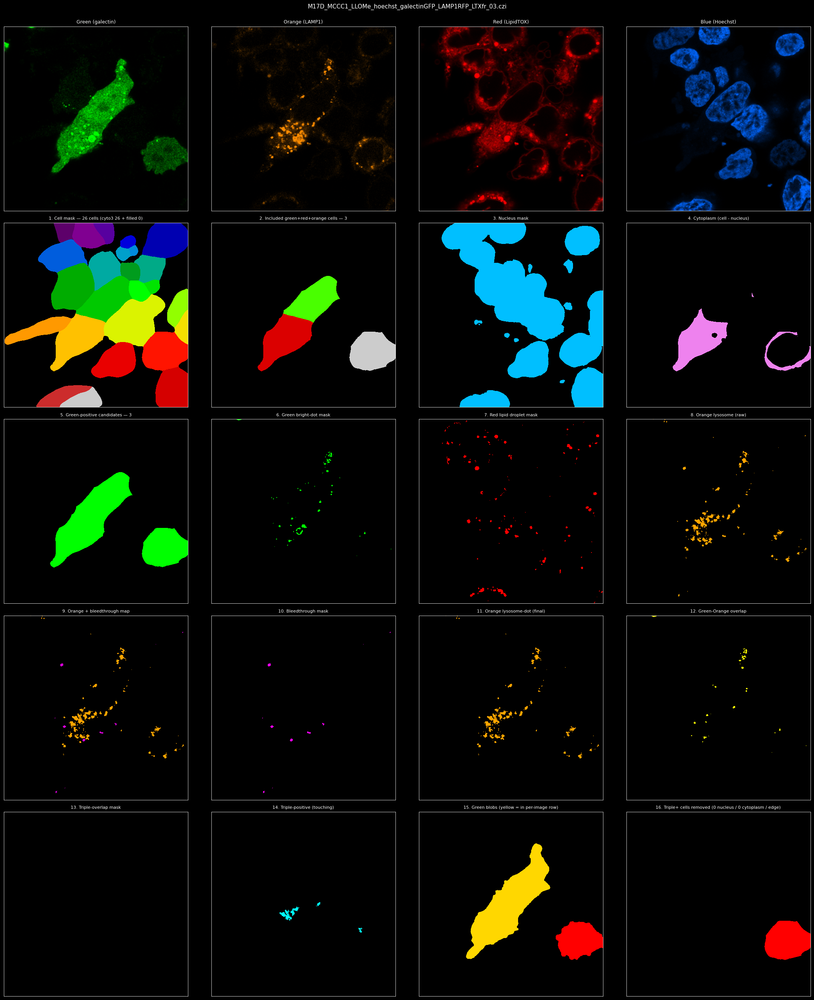


Processing: M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_04.czi


    Cells (cyto3 orange+red, composite-only): 16


    Nucleus (cellpose 17 + intensity union): 401442 px
    Hybrid cells: 21 (+5 recovered)
    Green-positive cells: 4 / 21 (fill >= 0.5)


    Included triple-positive cells: 3 / 4 green-positive (red area >= 6, orange area >= 6)
    Green-positive but excluded (missing red/orange): [7]
    Exported cells: 3 / 3 triple-positive


    Green blobs: 1 / 1 in per-image row; nuclei counted: 1
    saved masks -> Results/masks/galectin test images/M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_04


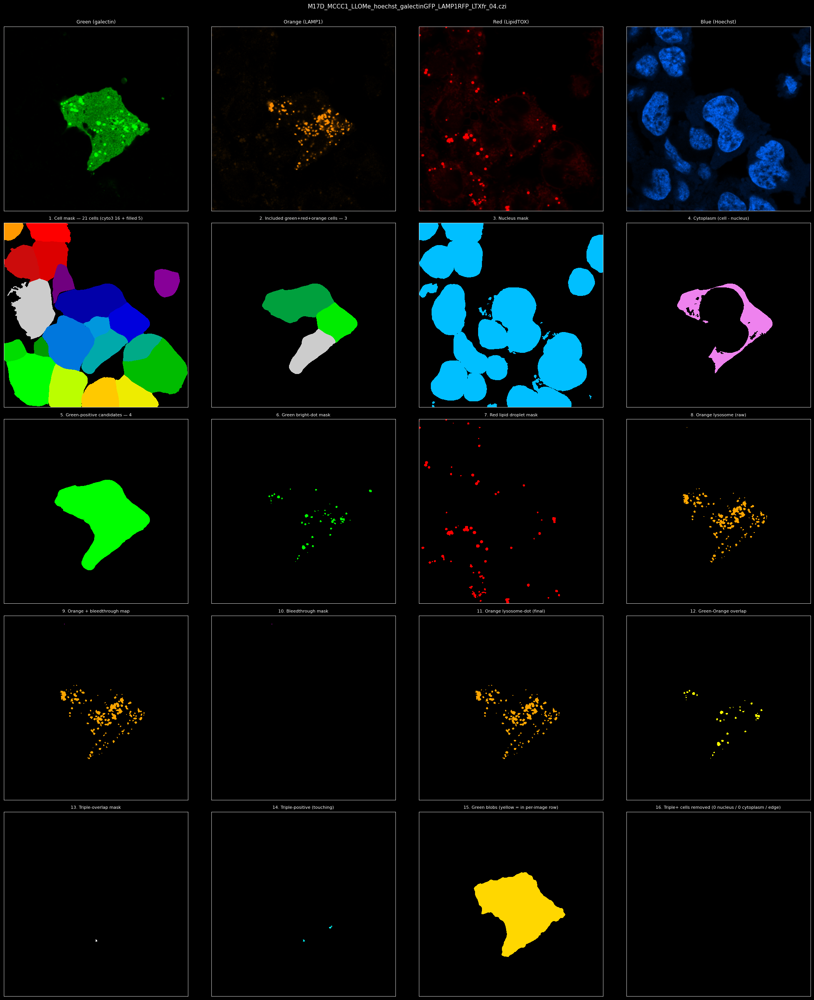


Processing: M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_05.czi


    Cells (cyto3 orange+red, composite-only): 23


    Nucleus (cellpose 14 + intensity union): 359931 px
    Hybrid cells: 23 (+0 recovered)
    Green-positive cells: 2 / 23 (fill >= 0.5)


    Included triple-positive cells: 2 / 2 green-positive (red area >= 6, orange area >= 6)
    Exported cells: 2 / 2 triple-positive


    Green blobs: 1 / 1 in per-image row; nuclei counted: 3
    saved masks -> Results/masks/galectin test images/M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_05


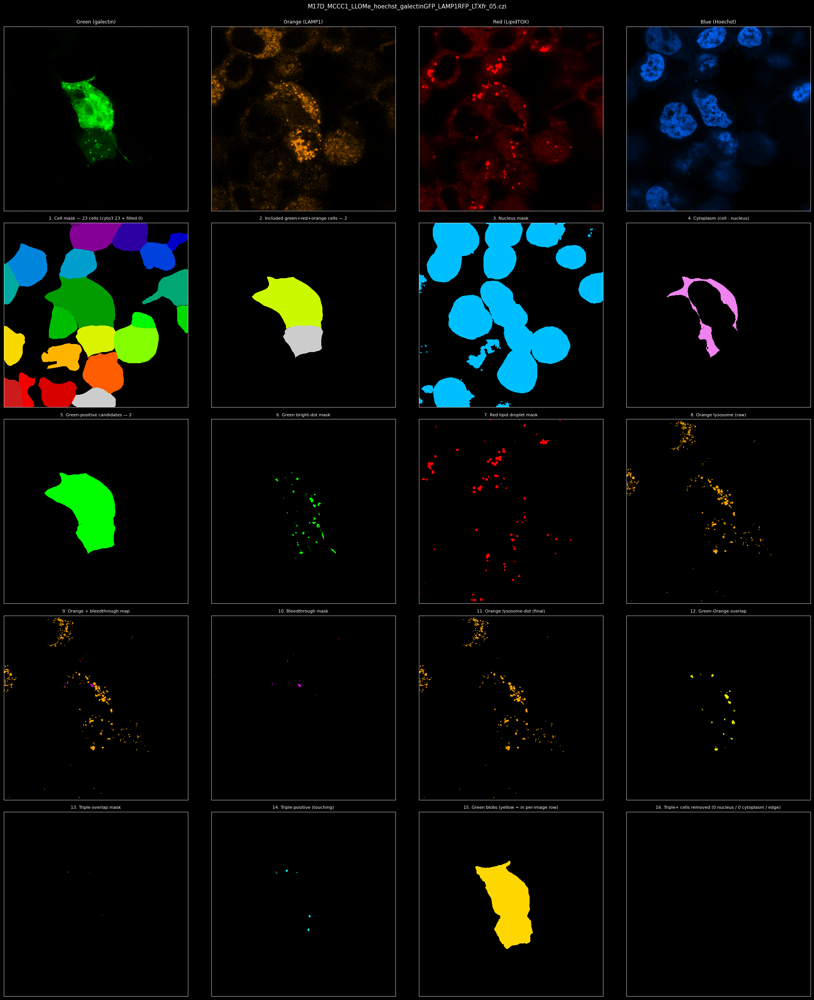


Processing: M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_06.czi


    Cells (cyto3 orange+red, composite-only): 25


    Nucleus (cellpose 24 + intensity union): 536023 px
    Hybrid cells: 36 (+11 recovered)
    Green-positive cells: 2 / 36 (fill >= 0.5)


    Included triple-positive cells: 1 / 2 green-positive (red area >= 6, orange area >= 6)
    Green-positive but excluded (missing red/orange): [21]
    Exported cells: 1 / 1 triple-positive
    Green blobs: 1 / 1 in per-image row; nuclei counted: 1
    saved masks -> Results/masks/galectin test images/M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_06


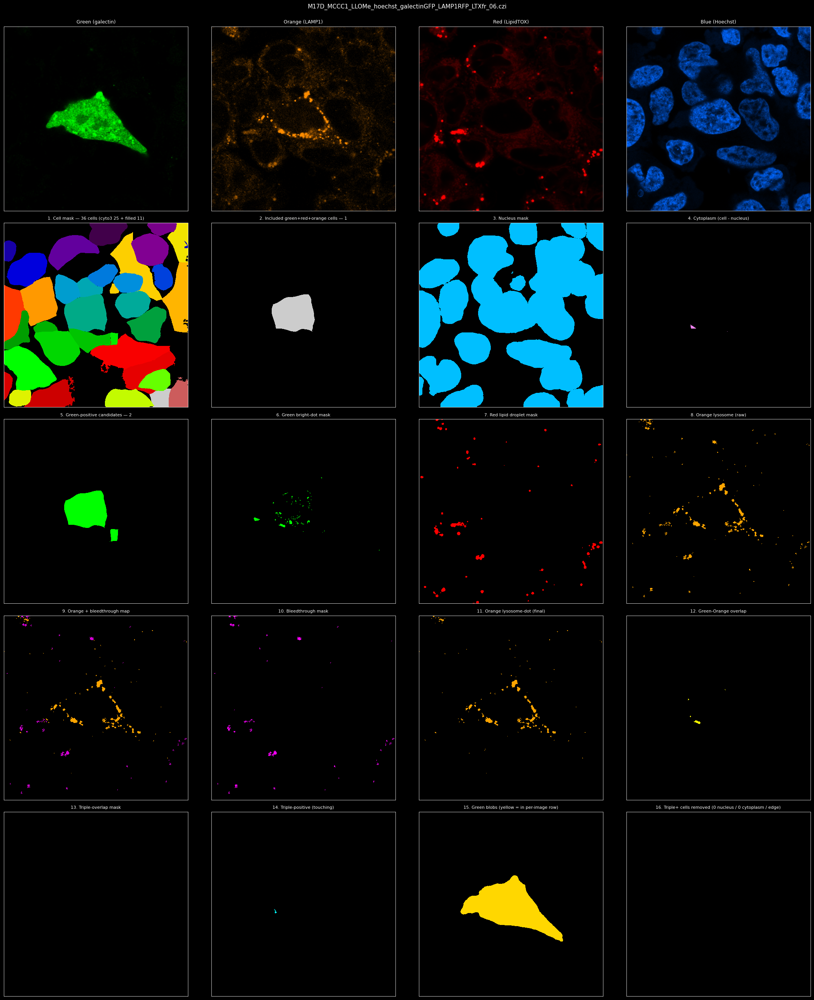


Processing: M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_07.czi


    Cells (cyto3 orange+red, composite-only): 11


    Nucleus (cellpose 22 + intensity union): 423841 px
    Hybrid cells: 25 (+14 recovered)
    Green-positive cells: 3 / 25 (fill >= 0.5)


    Included triple-positive cells: 2 / 3 green-positive (red area >= 6, orange area >= 6)
    Green-positive but excluded (missing red/orange): [3]
    Exported cells: 2 / 2 triple-positive


    Green blobs: 1 / 2 in per-image row; nuclei counted: 2
    saved masks -> Results/masks/galectin test images/M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_07


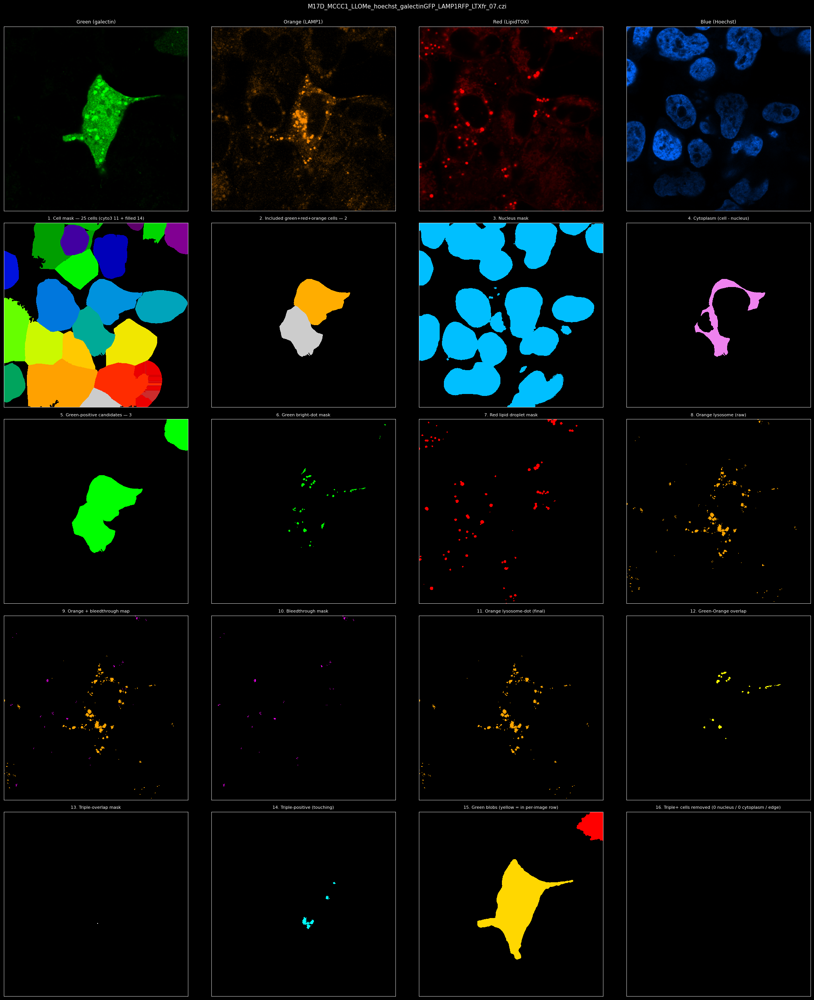


Processing: M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_08.czi


    Cells (cyto3 orange+red, composite-only): 3


    Nucleus (cellpose 11 + intensity union): 161137 px
    Hybrid cells: 14 (+11 recovered)
    Green-positive cells: 1 / 14 (fill >= 0.5)


    Included triple-positive cells: 1 / 1 green-positive (red area >= 6, orange area >= 6)
    Exported cells: 1 / 1 triple-positive
    Green blobs: 1 / 1 in per-image row; nuclei counted: 0
    saved masks -> Results/masks/galectin test images/M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_08


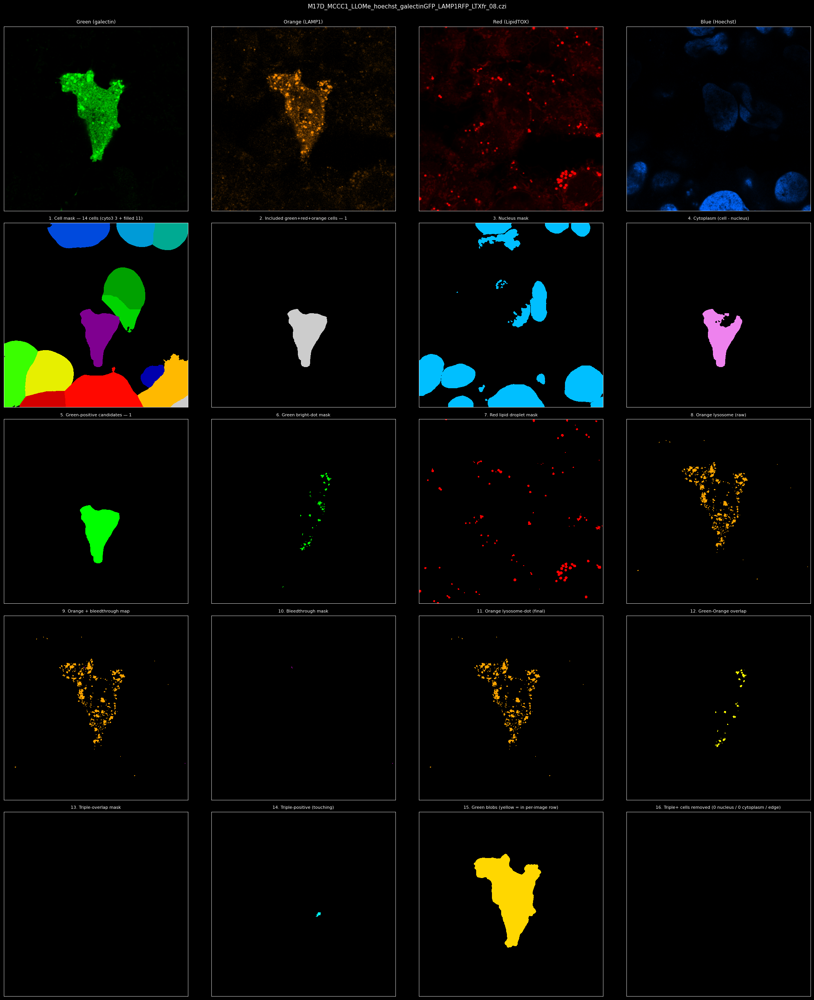


Processing: M17D_SCR_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_01.czi


    Cells (cyto3 orange+red, composite-only): 17


    Nucleus (cellpose 20 + intensity union): 488245 px
    Hybrid cells: 25 (+8 recovered)
    Green-positive cells: 3 / 25 (fill >= 0.5)


    Included triple-positive cells: 2 / 3 green-positive (red area >= 6, orange area >= 6)
    Green-positive but excluded (missing red/orange): [20]
    Exported cells: 1 / 2 triple-positive (removed [21]: 0 nucleus / 0 cytoplasm / edge)


    Green blobs: 1 / 2 in per-image row; nuclei counted: 1
    saved masks -> Results/masks/galectin test images/M17D_SCR_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_01


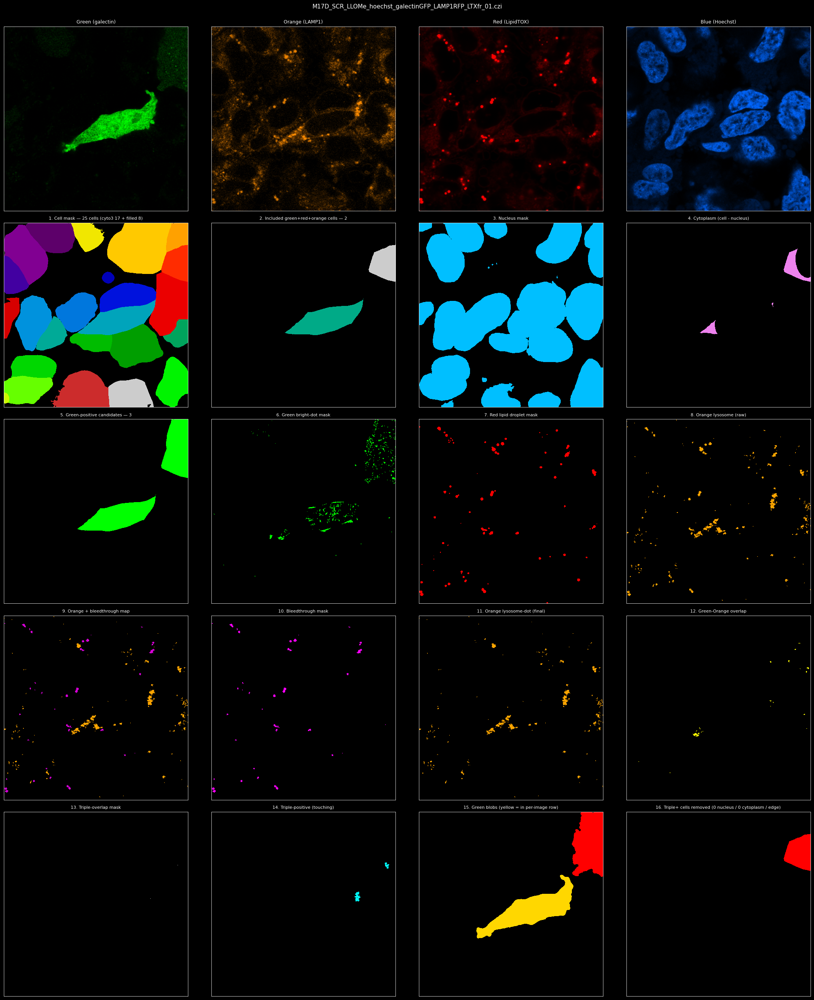


Processing: M17D_SCR_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_02.czi


    Cells (cyto3 orange+red, composite-only): 22


    Nucleus (cellpose 20 + intensity union): 474653 px
    Hybrid cells: 26 (+4 recovered)
    Green-positive cells: 5 / 26 (fill >= 0.5)


    Included triple-positive cells: 3 / 5 green-positive (red area >= 6, orange area >= 6)
    Green-positive but excluded (missing red/orange): [8, 16]
    Exported cells: 3 / 3 triple-positive


    Green blobs: 2 / 2 in per-image row; nuclei counted: 3
    saved masks -> Results/masks/galectin test images/M17D_SCR_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_02


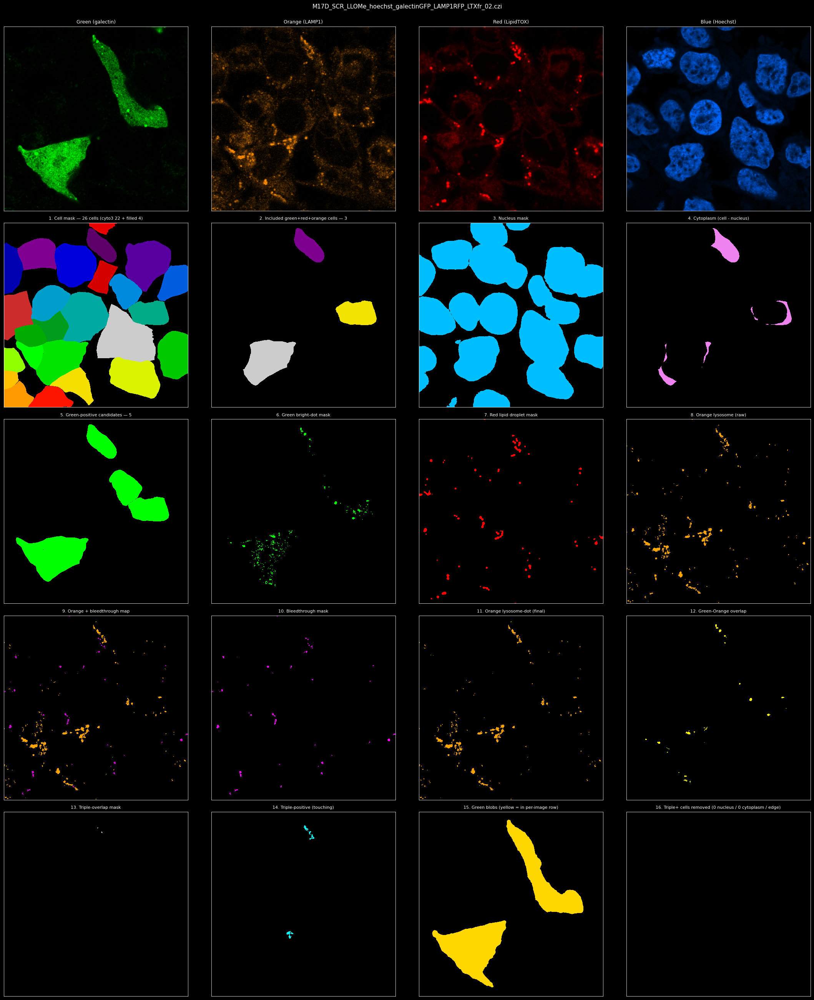


Processing: M17D_SCR_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_03.czi


    Cells (cyto3 orange+red, composite-only): 20


    Nucleus (cellpose 18 + intensity union): 355075 px
    Hybrid cells: 26 (+6 recovered)
    Green-positive cells: 5 / 26 (fill >= 0.5)


    Included triple-positive cells: 4 / 5 green-positive (red area >= 6, orange area >= 6)
    Green-positive but excluded (missing red/orange): [5]
    Exported cells: 3 / 4 triple-positive (removed [1]: 0 nucleus / 0 cytoplasm / edge)


    Green blobs: 2 / 3 in per-image row; nuclei counted: 4
    saved masks -> Results/masks/galectin test images/M17D_SCR_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_03


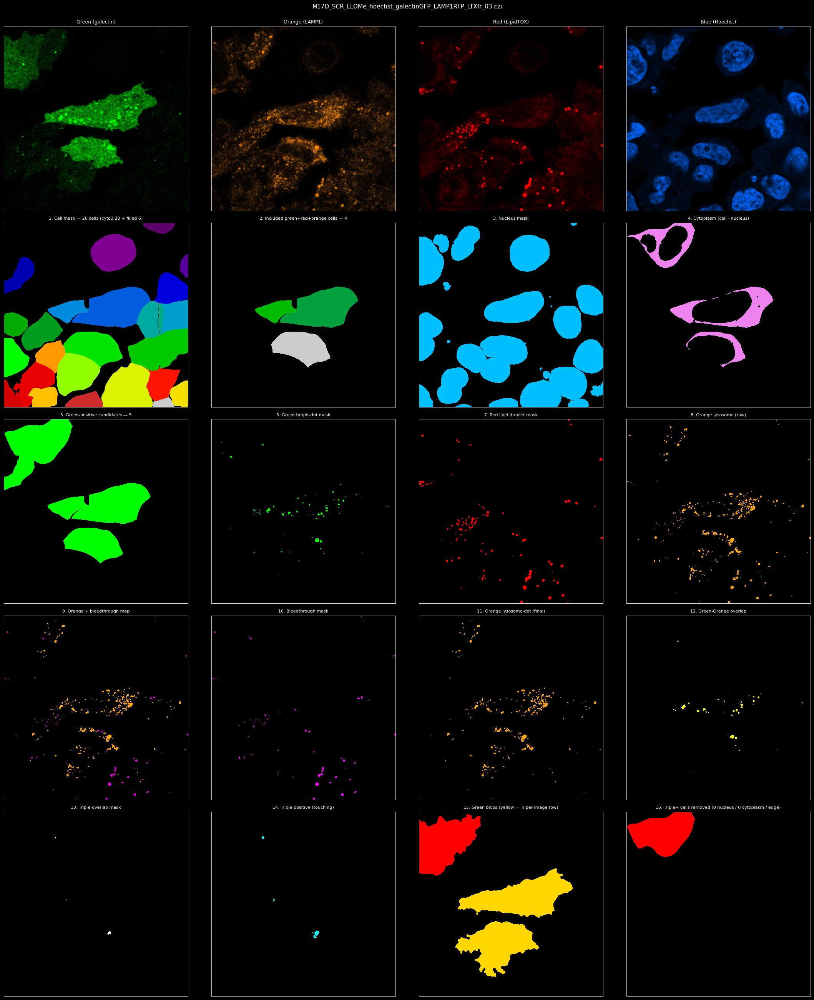


Processing: M17D_SCR_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_04.czi


    Cells (cyto3 orange+red, composite-only): 23


    Nucleus (cellpose 17 + intensity union): 440142 px
    Hybrid cells: 24 (+1 recovered)
    Green-positive cells: 1 / 24 (fill >= 0.5)


    Included triple-positive cells: 1 / 1 green-positive (red area >= 6, orange area >= 6)
    Exported cells: 1 / 1 triple-positive
    Green blobs: 1 / 2 in per-image row; nuclei counted: 1
    saved masks -> Results/masks/galectin test images/M17D_SCR_LLOMe_hoechst_galectinGFP_LAMP1RFP_LTXfr_04


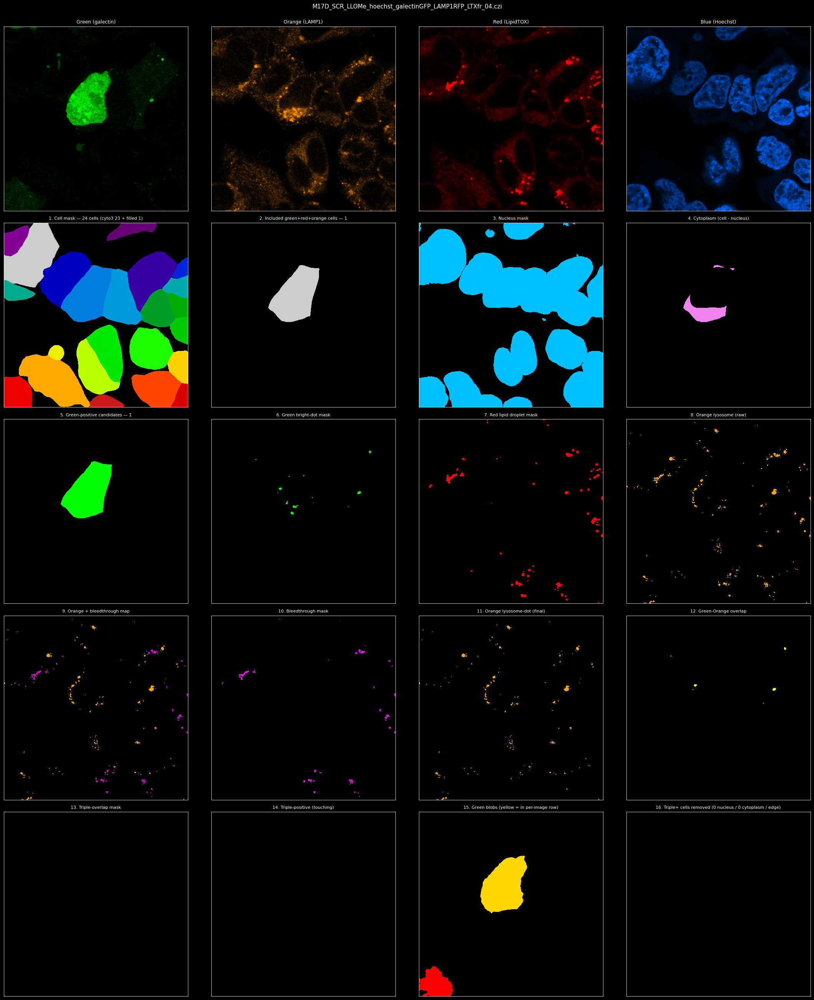

  -> 19 triple-positive cell row(s) saved to Results/galectin test images_galectin_LAMP1_lipidtox_analysis.csv
  -> 10 per-image blob row(s) saved to Results/galectin test images_galectin_LAMP1_lipidtox_per_image_blob.csv

[skip] './M17D_52926_siRNA_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst' not found

[skip] './M17D_60426_siRNA_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst' not found

[skip] './M17D_60526_siRNA_OA_Fed_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst' not found

[skip] './M17D_60926_siRNA_OA_Fed_galectinGFP_LAMP1RFP_LipidTOXfr_Hoechst' not found

[skip] './M17D_61126_siRNA_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst' not found

[skip] './M17D_61826_siRNA_galectinGFP_LAMP1RFP_LipidTOXfr_hoechst' not found

[skip] './M17D_61826_siRNA_OA_Fed_galectinGFP_LAMP1RFP_LipidTOXfr_Hoechst' not found

All folders processed; masks and eligibility in Results/masks/<folder>/<image>/.


,Filename,Cell_ID,Cell_Area_px,Cytoplasm_Area_px,Nucleus_Area_px,N_Green_Dots,Green_Dot_Area_px,Green_Dot_MFI,Green_WholeCell_MFI,Green_EntireCell_MFI,...,N_TriplePositive_Touching,Green_Fill_Fraction,Green_Positive,Red_Positive_Area_px,Red_Positive,Orange_Positive_Area_px,Orange_Positive,Triple_Positive_Cell,N_Nuclei,Touches_Image_Edge
0,M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_...,14,37270,615,36655,7,420,15087.688,1984.636,3208.509,...,1,0.999222,True,9,True,1089,True,True,1,False
1,M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_...,20,44767,41972,2795,13,1222,17315.390,3057.102,3080.938,...,2,0.952376,True,1003,True,5956,True,True,0,False
2,M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_...,4,49854,18619,31235,11,599,41743.107,11167.642,12164.678,...,0,0.910960,True,286,True,3222,True,True,0,False
3,M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_...,5,26663,18633,8030,19,1311,50247.860,14100.486,14446.157,...,0,0.906087,True,576,True,4954,True,True,0,False
4,M17D_MCCC1_LLOMe_hoechst_galectinGFP_LAMP1RFP_...,8,26609,8910,17699,9,757,45412.655,10423.460,11216.494,...,2,0.855087,True,249,True,1413,True,True,0,False


In [8]:
def analyze_folder(image_folder):
    """Process one folder and write one CSV."""
    folder_tag = os.path.basename(os.path.normpath(image_folder))
    mask_dir = os.path.join(MASK_FOLDER, folder_tag)
    os.makedirs(mask_dir, exist_ok=True)

    image_files = sorted(glob.glob(os.path.join(image_folder, FILE_EXTENSION)))
    print(f"---------- {folder_tag}: {len(image_files)} image(s) ----------")

    rows = []
    selected_pairs = []
    blob_rows = []
    for filepath in image_files:
        result = segment_one_image(filepath, mask_dir)
        if result is None:
            continue
        for cid in result["export_ids"]:
            row = analyze_cell(cid, result["labeled_cells"], result["masks"], result["raw"])
            row.update(result["eligibility"][cid])
            row.pop("Excluded_Reason")
            row["Filename"] = os.path.basename(filepath)
            rows.append(row)
            selected_pairs.append((row["Filename"], cid))
        if result["blob_row"] is not None:
            blob_rows.append({"Filename": os.path.basename(filepath), **result["blob_row"]})

    if rows:
        df = pd.DataFrame(rows)
        front = ["Filename", "Cell_ID"]
        df = df[front + [c for c in df.columns if c not in front]]
    else:
        df = pd.DataFrame()

    if len(df) != len(selected_pairs):
        raise RuntimeError("Export row count does not match selected triple-positive cells")
    if len(df) and not bool(df["Triple_Positive_Cell"].all()):
        raise RuntimeError("A non-triple-positive cell reached the export table")
    if len(df) and ((df["Nucleus_Area_px"] == 0) | (df["Cytoplasm_Area_px"] == 0)).any():
        raise RuntimeError("A cell with 0 nucleus or 0 cytoplasm reached the export table")

    out_csv = os.path.join(RESULTS_FOLDER, f"{folder_tag}_{CSV_SUFFIX}")
    df.to_csv(out_csv, index=False)
    print(f"  -> {len(df)} triple-positive cell row(s) saved to {out_csv}")

    blob_df = pd.DataFrame(blob_rows)
    if len(blob_df) and ((blob_df["Nucleus_Area_px"] == 0) | (blob_df["Cytoplasm_Area_px"] == 0)).any():
        raise RuntimeError("A blob with 0 nucleus or 0 cytoplasm reached the per-image table")
    blob_csv = os.path.join(RESULTS_FOLDER, f"{folder_tag}_{BLOB_CSV_SUFFIX}")
    blob_df.to_csv(blob_csv, index=False)
    print(f"  -> {len(blob_df)} per-image blob row(s) saved to {blob_csv}\n")
    return df


last_df = None
for image_folder in IMAGE_FOLDERS:
    folder_tag = os.path.basename(os.path.normpath(image_folder))
    if not os.path.isdir(image_folder):
        print(f"[skip] '{image_folder}' not found\n")
        continue
    print(f"{folder_tag}: START")
    last_df = analyze_folder(image_folder)

print("All folders processed; "
      "masks and eligibility in Results/masks/<folder>/<image>/.")
last_df.head() if last_df is not None else None

## Output summary

In [9]:
# Summary of what the driver wrote.
for suffix, kind in ((CSV_SUFFIX, "cell"), (BLOB_CSV_SUFFIX, "per-image blob")):
    csv_files = sorted(glob.glob(os.path.join(RESULTS_FOLDER, f"*_{suffix}")))
    print(f"{len(csv_files)} {kind} CSV file(s) in {RESULTS_FOLDER}/:")
    total_rows = 0
    for f in csv_files:
        try:
            n = len(pd.read_csv(f))
        except pd.errors.EmptyDataError:  # folder with no exported rows
            n = 0
        total_rows += n
        print(f"  {os.path.basename(f):75s} {n:>4d} {kind} row(s)")
    print(f"  {'TOTAL':75s} {total_rows:>4d}")

1 cell CSV file(s) in Results/:
  galectin test images_galectin_LAMP1_lipidtox_analysis.csv                     19 cell row(s)
  TOTAL                                                                         19
1 per-image blob CSV file(s) in Results/:
  galectin test images_galectin_LAMP1_lipidtox_per_image_blob.csv               10 per-image blob row(s)
  TOTAL                                                                         10
